In [32]:
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

In [33]:
insurance_data = pd.read_csv("insurance.csv")
X = insurance_data.drop(columns=["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X, columns=["region"], drop_first=True ,dtype=int)

X["sex"] = X["sex"].map({"female": 1, "male": 0})
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})

X["age_smoker"] = X["age"] = X["smoker"]
X["bmi_smoker"] = X["bmi"] = X["smoker"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


MSE: for alpha=0.001:  52262073.38373046
MSE: for alpha=0.1:  52260963.95871192
MSE: for alpha=1:  52259718.04290672
MSE: for alpha=2:  52261718.38667337
MSE: for alpha=5:  52267977.51840266
MSE: for alpha=10:  52283745.596032836
MSE: for alpha=20:  52317470.630126566
MSE: for alpha=30:  52348590.324280426
MSE: for alpha=40:  52382213.24159009
MSE: for alpha=50:  52418338.87304108
MSE: for alpha=100:  52636505.31586471


<Axes: >

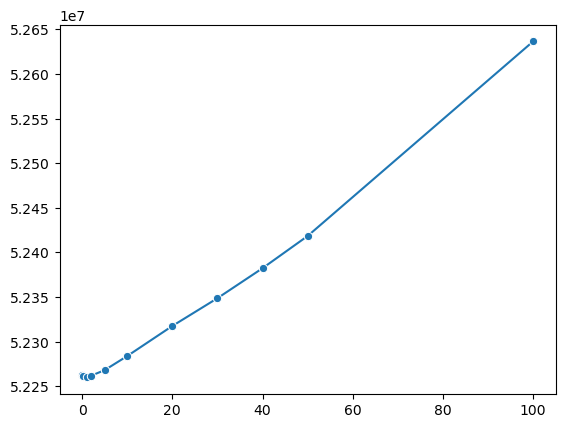

In [34]:
import seaborn as sns

alphas = [0.001,0.1,1,2,5,10,20,30,40,50,100]
mses = []

for a in alphas:
  lasso_model = Lasso(alpha = a)
  lasso_model.fit(X_train, y_train)

  y_pred = lasso_model.predict(X_test)
  mse = mean_squared_error(y_test, y_pred)
  print(f"MSE: for alpha={a}: ", mse)
  mses.append(mse)

sns.lineplot(x=alphas, y=mses, marker="o")

In [35]:
from sklearn.linear_model  import LassoCV
alphas = [0.001,0.1,1,2,5,10,20,30,40,50,100]
lasso_cv_model = LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)

lasso_cv_model.fit(X_train,y_train)

print("best alpha: ", lasso_cv_model.alpha_)

y_pred =lasso_cv_model.predict(X_test)
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)
print("mse= ",mse)
print("s2 = ",r2) 

best alpha:  53.686530688816006
mse=  52432288.08035445
s2 =  0.6622691369099347
